# LavaSmart · Los dos modelos de Machine Learning, paso a paso

**AquaBrillo**, lavadero de autos en Lima. LavaSmart registra cada lavado (placa, servicios, cobro y entrega) y, una vez por semana, entrena dos modelos con esos registros:

| | Modelo 1 · Predicción de demanda | Modelo 2 · Segmentación de clientes |
|---|---|---|
| **Pregunta del dueño** | ¿Cuántos autos llegarán cada día? | ¿Quiénes son mis clientes y cuánto valen? |
| **Tipo de aprendizaje** | Supervisado (regresión) | No supervisado (agrupamiento) |
| **Modelo** | Ridge (regresión lineal), comparado con Random Forest | K-Means sobre RFM |
| **Lo que entrega** | Autos esperados para los próximos 14 días | Cada cliente en un segmento |

> **Sobre los datos.** El lavadero todavía no tiene histórico digital (el cuaderno solo anotaba trabajador, monto y día). Este notebook usa los **3 meses de histórico simulado** del entorno de desarrollo: 13/08 al 12/11/2026, 1 111 lavados y 443 clientes. Los clientes van con un número, sin placa. Con datos reales cambian los valores, no el método.

Es el mismo código que corre en el sistema (`ml/demanda.py` y `ml/segmentacion.py`), aquí separado en pasos para ver qué hace cada parte. Para ejecutarlo: **Entorno de ejecución → Ejecutar todas**.

## 0. Librerías

| Librería | Para qué se usa aquí |
|---|---|
| **pandas** | Tablas de datos: agrupar lavados por día y por cliente |
| **numpy** | Cálculos numéricos: errores, logaritmos, promedios |
| **scikit-learn** | Los modelos: `Ridge`, `RandomForestRegressor`, `KMeans`, `StandardScaler` y la métrica `silhouette_score` |
| **matplotlib** | Los gráficos |

Las cuatro vienen instaladas en Colab.

In [1]:
import io
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from sklearn.linear_model import Ridge                  # Modelo 1
from sklearn.ensemble import RandomForestRegressor      # Modelo 1 (candidato)
from sklearn.cluster import KMeans                      # Modelo 2
from sklearn.preprocessing import StandardScaler        # Modelo 2
from sklearn.metrics import silhouette_score            # Modelo 2

# Colores de LavaSmart
MARCA, ACENTO, NARANJA, GRIS = "#0B2545", "#0891B2", "#F59E0B", "#9AA5B1"
plt.rcParams.update({"figure.figsize": (12, 5), "font.size": 12,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlecolor": MARCA})

## 1. Los datos: un lavado por fila

Cada fila es un auto entregado: **qué cliente**, **qué día** y **cuánto pagó**. Es lo que el sistema guarda en la tabla `lavado` al entregar el auto.

In [2]:
# @title Histórico simulado (1 111 lavados) { display-mode: "form" }
DATOS = """
cliente,dia,monto
1,2026-08-13,20.0
2,2026-08-13,24.0
3,2026-08-13,24.0
4,2026-08-13,30.0
5,2026-08-13,20.0
1,2026-08-14,15.0
6,2026-08-14,20.0
7,2026-08-14,15.0
8,2026-08-14,20.0
9,2026-08-14,15.0
10,2026-08-14,30.0
11,2026-08-14,24.0
12,2026-08-14,30.0
13,2026-08-14,22.0
14,2026-08-15,20.0
15,2026-08-15,20.0
16,2026-08-15,15.0
17,2026-08-15,49.0
18,2026-08-15,25.0
19,2026-08-15,24.0
20,2026-08-15,20.0
21,2026-08-15,20.0
22,2026-08-15,35.0
23,2026-08-15,35.0
24,2026-08-15,22.0
25,2026-08-15,43.0
26,2026-08-15,20.0
27,2026-08-15,20.0
28,2026-08-15,17.0
29,2026-08-15,20.0
30,2026-08-15,24.0
31,2026-08-15,25.0
32,2026-08-15,16.0
33,2026-08-15,40.0
1,2026-08-16,15.0
34,2026-08-16,15.0
35,2026-08-16,36.0
36,2026-08-16,31.0
37,2026-08-16,25.0
38,2026-08-16,18.0
39,2026-08-16,24.0
40,2026-08-16,20.0
41,2026-08-16,25.0
42,2026-08-16,18.0
43,2026-08-16,17.0
44,2026-08-16,24.0
45,2026-08-16,22.0
46,2026-08-16,35.0
47,2026-08-16,24.0
48,2026-08-16,49.0
49,2026-08-16,15.0
50,2026-08-16,24.0
51,2026-08-16,22.0
52,2026-08-17,25.0
9,2026-08-17,15.0
53,2026-08-17,36.0
54,2026-08-17,25.0
55,2026-08-17,35.0
56,2026-08-17,20.0
57,2026-08-17,15.0
58,2026-08-17,20.0
59,2026-08-17,24.0
1,2026-08-18,15.0
49,2026-08-18,15.0
60,2026-08-18,15.0
61,2026-08-18,16.0
62,2026-08-19,20.0
63,2026-08-19,20.0
9,2026-08-19,15.0
64,2026-08-19,20.0
65,2026-08-19,20.0
66,2026-08-19,20.0
67,2026-08-19,25.0
68,2026-08-19,37.0
69,2026-08-19,37.0
70,2026-08-19,24.0
71,2026-08-20,32.0
72,2026-08-20,22.0
73,2026-08-20,24.0
74,2026-08-20,17.0
75,2026-08-20,24.0
76,2026-08-20,27.0
77,2026-08-20,15.0
78,2026-08-20,25.0
79,2026-08-20,25.0
80,2026-08-20,17.0
81,2026-08-21,24.0
82,2026-08-21,22.0
16,2026-08-21,20.0
83,2026-08-21,24.0
84,2026-08-21,35.0
85,2026-08-21,36.0
86,2026-08-21,15.0
87,2026-08-21,15.0
88,2026-08-21,17.0
89,2026-08-21,20.0
90,2026-08-21,30.0
91,2026-08-22,16.0
92,2026-08-22,37.0
93,2026-08-22,24.0
94,2026-08-22,17.0
95,2026-08-22,15.0
96,2026-08-22,15.0
97,2026-08-22,25.0
98,2026-08-22,22.0
99,2026-08-22,18.0
100,2026-08-22,24.0
101,2026-08-22,25.0
102,2026-08-22,24.0
103,2026-08-22,18.0
9,2026-08-23,15.0
16,2026-08-23,20.0
49,2026-08-23,20.0
1,2026-08-23,15.0
104,2026-08-23,25.0
105,2026-08-23,16.0
106,2026-08-23,17.0
107,2026-08-23,25.0
108,2026-08-23,35.0
109,2026-08-23,20.0
110,2026-08-23,15.0
111,2026-08-23,15.0
112,2026-08-23,36.0
113,2026-08-23,24.0
114,2026-08-23,55.0
115,2026-08-23,32.0
116,2026-08-23,30.0
117,2026-08-24,24.0
118,2026-08-24,25.0
119,2026-08-24,24.0
120,2026-08-24,43.0
121,2026-08-24,43.0
122,2026-08-24,35.0
123,2026-08-24,43.0
124,2026-08-25,16.0
9,2026-08-25,15.0
22,2026-08-25,35.0
125,2026-08-25,45.0
126,2026-08-25,15.0
7,2026-08-26,15.0
9,2026-08-26,12.0
16,2026-08-26,15.0
127,2026-08-26,24.0
128,2026-08-26,15.0
1,2026-08-27,15.0
129,2026-08-27,15.0
63,2026-08-27,20.0
130,2026-08-27,30.0
131,2026-08-27,20.0
132,2026-08-27,20.0
133,2026-08-27,43.0
134,2026-08-27,15.0
135,2026-08-27,15.0
105,2026-08-28,16.0
81,2026-08-28,24.0
49,2026-08-28,15.0
45,2026-08-28,22.0
16,2026-08-28,15.0
136,2026-08-28,25.0
137,2026-08-28,20.0
138,2026-08-28,22.0
139,2026-08-28,20.0
140,2026-08-28,20.0
141,2026-08-28,36.0
142,2026-08-28,25.0
18,2026-08-29,25.0
41,2026-08-29,25.0
24,2026-08-29,22.0
143,2026-08-29,15.0
144,2026-08-29,20.0
145,2026-08-29,30.0
146,2026-08-29,34.0
147,2026-08-29,30.0
148,2026-08-29,15.0
149,2026-08-29,38.0
150,2026-08-29,20.0
151,2026-08-29,17.0
152,2026-08-29,22.0
153,2026-08-29,22.0
154,2026-08-29,17.0
155,2026-08-29,35.0
156,2026-08-30,20.0
34,2026-08-30,15.0
79,2026-08-30,25.0
64,2026-08-30,20.0
157,2026-08-30,20.0
158,2026-08-30,17.0
159,2026-08-30,30.0
160,2026-08-30,45.0
161,2026-08-30,32.0
162,2026-08-30,20.0
163,2026-08-30,32.0
164,2026-08-30,20.0
165,2026-08-30,24.0
166,2026-08-30,20.0
167,2026-08-30,25.0
168,2026-08-30,46.0
169,2026-08-30,16.0
170,2026-08-30,24.0
171,2026-08-30,20.0
172,2026-08-30,16.0
173,2026-08-30,24.0
174,2026-08-30,30.0
175,2026-08-30,20.0
52,2026-08-31,25.0
110,2026-08-31,20.0
56,2026-08-31,20.0
1,2026-08-31,20.0
9,2026-08-31,15.0
176,2026-08-31,15.0
82,2026-09-01,22.0
83,2026-09-01,24.0
101,2026-09-01,25.0
124,2026-09-01,16.0
177,2026-09-01,35.0
178,2026-09-01,15.0
179,2026-09-01,16.0
180,2026-09-01,24.0
16,2026-09-02,15.0
66,2026-09-02,20.0
27,2026-09-02,20.0
49,2026-09-02,15.0
62,2026-09-02,20.0
10,2026-09-02,20.0
169,2026-09-02,16.0
74,2026-09-03,17.0
181,2026-09-03,18.0
22,2026-09-03,35.0
9,2026-09-03,15.0
105,2026-09-03,16.0
182,2026-09-03,24.0
63,2026-09-03,20.0
17,2026-09-03,22.0
183,2026-09-03,20.0
184,2026-09-04,34.0
8,2026-09-04,20.0
172,2026-09-04,16.0
185,2026-09-04,15.0
13,2026-09-04,22.0
104,2026-09-04,25.0
169,2026-09-04,16.0
186,2026-09-04,15.0
187,2026-09-04,16.0
9,2026-09-05,13.0
16,2026-09-05,15.0
126,2026-09-05,15.0
81,2026-09-05,22.0
1,2026-09-05,15.0
188,2026-09-05,16.0
189,2026-09-05,22.0
190,2026-09-05,20.0
191,2026-09-05,24.0
192,2026-09-05,15.0
193,2026-09-05,35.0
194,2026-09-05,22.0
195,2026-09-05,24.0
196,2026-09-05,20.0
197,2026-09-05,22.0
198,2026-09-05,20.0
199,2026-09-05,36.0
200,2026-09-05,36.0
201,2026-09-05,25.0
202,2026-09-05,22.0
203,2026-09-05,37.0
204,2026-09-05,24.0
205,2026-09-05,24.0
206,2026-09-05,36.0
207,2026-09-05,22.0
208,2026-09-05,24.0
110,2026-09-06,20.0
169,2026-09-06,16.0
79,2026-09-06,25.0
175,2026-09-06,20.0
49,2026-09-06,15.0
209,2026-09-06,22.0
172,2026-09-06,16.0
9,2026-09-06,15.0
210,2026-09-06,24.0
211,2026-09-06,30.0
212,2026-09-06,20.0
213,2026-09-06,15.0
214,2026-09-06,39.0
215,2026-09-06,43.0
216,2026-09-06,17.0
105,2026-09-07,16.0
217,2026-09-07,15.0
49,2026-09-07,15.0
218,2026-09-07,25.0
219,2026-09-07,34.0
220,2026-09-07,24.0
221,2026-09-07,20.0
222,2026-09-08,25.0
223,2026-09-08,30.0
224,2026-09-08,25.0
64,2026-09-08,20.0
124,2026-09-08,16.0
188,2026-09-08,16.0
7,2026-09-08,15.0
169,2026-09-09,16.0
225,2026-09-09,43.0
226,2026-09-09,15.0
140,2026-09-09,20.0
9,2026-09-09,15.0
16,2026-09-09,20.0
23,2026-09-09,15.0
24,2026-09-09,22.0
227,2026-09-09,34.0
170,2026-09-10,24.0
1,2026-09-10,15.0
228,2026-09-10,25.0
172,2026-09-10,16.0
229,2026-09-10,30.0
101,2026-09-10,25.0
19,2026-09-10,43.0
133,2026-09-10,43.0
45,2026-09-11,22.0
230,2026-09-11,30.0
169,2026-09-11,16.0
22,2026-09-11,35.0
231,2026-09-11,43.0
232,2026-09-11,16.0
233,2026-09-11,20.0
234,2026-09-11,22.0
235,2026-09-11,20.0
236,2026-09-11,24.0
237,2026-09-11,15.0
83,2026-09-12,24.0
52,2026-09-12,25.0
70,2026-09-12,34.0
41,2026-09-12,25.0
49,2026-09-12,15.0
238,2026-09-12,36.0
239,2026-09-12,24.0
240,2026-09-12,20.0
241,2026-09-12,25.0
242,2026-09-12,20.0
243,2026-09-12,15.0
244,2026-09-12,18.0
245,2026-09-12,20.0
246,2026-09-12,22.0
247,2026-09-12,32.0
248,2026-09-12,16.0
249,2026-09-12,16.0
250,2026-09-12,20.0
251,2026-09-12,17.0
252,2026-09-12,24.0
253,2026-09-12,25.0
254,2026-09-12,20.0
255,2026-09-12,39.0
188,2026-09-13,16.0
56,2026-09-13,20.0
105,2026-09-13,16.0
256,2026-09-13,22.0
212,2026-09-13,20.0
172,2026-09-13,16.0
175,2026-09-13,20.0
9,2026-09-13,15.0
257,2026-09-13,16.0
96,2026-09-13,25.0
34,2026-09-13,15.0
258,2026-09-13,20.0
259,2026-09-13,15.0
260,2026-09-13,17.0
261,2026-09-13,20.0
110,2026-09-14,15.0
74,2026-09-14,17.0
16,2026-09-14,20.0
262,2026-09-14,33.0
263,2026-09-14,22.0
188,2026-09-14,16.0
104,2026-09-14,23.0
82,2026-09-14,22.0
20,2026-09-14,20.0
172,2026-09-14,16.0
1,2026-09-14,15.0
172,2026-09-15,22.0
9,2026-09-15,20.0
194,2026-09-15,22.0
264,2026-09-15,25.0
265,2026-09-15,20.0
266,2026-09-15,25.0
1,2026-09-16,20.0
66,2026-09-16,18.0
267,2026-09-16,22.0
63,2026-09-16,20.0
72,2026-09-16,22.0
188,2026-09-16,22.0
92,2026-09-16,25.0
249,2026-09-17,16.0
79,2026-09-17,25.0
268,2026-09-17,34.0
18,2026-09-17,25.0
62,2026-09-17,20.0
169,2026-09-17,22.0
40,2026-09-17,30.0
209,2026-09-17,22.0
81,2026-09-17,24.0
269,2026-09-17,30.0
49,2026-09-18,15.0
110,2026-09-18,15.0
91,2026-09-18,25.0
124,2026-09-18,16.0
53,2026-09-18,17.0
235,2026-09-18,20.0
140,2026-09-18,20.0
106,2026-09-18,17.0
126,2026-09-18,15.0
2,2026-09-18,34.0
270,2026-09-18,24.0
27,2026-09-19,20.0
87,2026-09-19,20.0
131,2026-09-19,25.0
4,2026-09-19,35.0
195,2026-09-19,24.0
119,2026-09-19,24.0
271,2026-09-19,45.0
24,2026-09-19,22.0
101,2026-09-19,25.0
16,2026-09-19,20.0
272,2026-09-19,15.0
273,2026-09-19,35.0
274,2026-09-19,35.0
275,2026-09-19,22.0
276,2026-09-19,20.0
277,2026-09-19,34.0
278,2026-09-19,45.0
9,2026-09-20,15.0
112,2026-09-20,25.0
279,2026-09-20,43.0
172,2026-09-20,16.0
136,2026-09-20,25.0
175,2026-09-20,20.0
41,2026-09-20,25.0
64,2026-09-20,20.0
170,2026-09-20,24.0
188,2026-09-20,12.0
5,2026-09-20,20.0
280,2026-09-20,24.0
281,2026-09-20,36.0
282,2026-09-20,25.0
283,2026-09-20,17.0
284,2026-09-20,17.0
285,2026-09-20,20.0
286,2026-09-20,45.0
287,2026-09-21,24.0
288,2026-09-21,24.0
289,2026-09-21,16.0
1,2026-09-21,15.0
118,2026-09-21,18.0
220,2026-09-21,24.0
49,2026-09-21,15.0
105,2026-09-21,16.0
123,2026-09-21,24.0
22,2026-09-22,35.0
9,2026-09-22,20.0
111,2026-09-22,41.0
290,2026-09-22,28.0
291,2026-09-22,16.0
172,2026-09-23,16.0
16,2026-09-23,20.0
12,2026-09-23,20.0
258,2026-09-23,20.0
292,2026-09-23,24.0
188,2026-09-23,11.0
55,2026-09-23,15.0
293,2026-09-23,20.0
132,2026-09-23,15.0
7,2026-09-24,15.0
212,2026-09-24,20.0
58,2026-09-24,20.0
249,2026-09-24,16.0
135,2026-09-24,15.0
45,2026-09-24,22.0
110,2026-09-24,15.0
167,2026-09-24,45.0
81,2026-09-25,24.0
228,2026-09-25,25.0
137,2026-09-25,20.0
133,2026-09-25,43.0
294,2026-09-25,24.0
295,2026-09-25,25.0
49,2026-09-25,15.0
10,2026-09-25,15.0
150,2026-09-26,20.0
172,2026-09-26,22.0
179,2026-09-26,22.0
9,2026-09-26,15.0
49,2026-09-26,15.0
1,2026-09-26,20.0
16,2026-09-26,15.0
101,2026-09-26,25.0
296,2026-09-26,25.0
56,2026-09-26,20.0
194,2026-09-26,22.0
297,2026-09-26,17.0
169,2026-09-26,16.0
17,2026-09-26,16.0
298,2026-09-26,45.0
125,2026-09-26,36.0
37,2026-09-26,57.0
299,2026-09-26,20.0
104,2026-09-26,25.0
300,2026-09-27,30.0
8,2026-09-27,15.0
121,2026-09-27,22.0
209,2026-09-27,22.0
170,2026-09-27,24.0
52,2026-09-27,25.0
13,2026-09-27,22.0
9,2026-09-27,15.0
61,2026-09-27,27.0
301,2026-09-27,24.0
302,2026-09-27,34.0
105,2026-09-27,16.0
156,2026-09-27,30.0
303,2026-09-27,25.0
83,2026-09-27,24.0
175,2026-09-27,20.0
74,2026-09-27,17.0
145,2026-09-27,25.0
304,2026-09-27,15.0
305,2026-09-27,18.0
39,2026-09-27,34.0
59,2026-09-28,24.0
79,2026-09-28,25.0
249,2026-09-28,16.0
306,2026-09-28,25.0
63,2026-09-28,20.0
188,2026-09-28,16.0
49,2026-09-28,15.0
307,2026-09-28,17.0
308,2026-09-28,45.0
309,2026-09-29,20.0
80,2026-09-29,24.0
64,2026-09-29,20.0
77,2026-09-29,20.0
126,2026-09-29,15.0
273,2026-09-29,35.0
235,2026-09-29,20.0
201,2026-09-29,25.0
82,2026-09-29,22.0
140,2026-09-29,20.0
310,2026-09-30,15.0
270,2026-09-30,24.0
311,2026-09-30,32.0
275,2026-09-30,22.0
62,2026-09-30,20.0
172,2026-09-30,16.0
41,2026-09-30,25.0
188,2026-09-30,16.0
124,2026-09-30,16.0
33,2026-09-30,20.0
16,2026-10-01,15.0
182,2026-10-01,24.0
113,2026-10-01,24.0
312,2026-10-01,36.0
34,2026-10-01,15.0
196,2026-10-01,35.0
313,2026-10-01,36.0
18,2026-10-01,25.0
158,2026-10-01,20.0
1,2026-10-01,20.0
144,2026-10-01,20.0
110,2026-10-02,15.0
1,2026-10-02,15.0
216,2026-10-02,17.0
205,2026-10-02,43.0
146,2026-10-02,17.0
169,2026-10-02,16.0
9,2026-10-02,20.0
24,2026-10-02,22.0
181,2026-10-02,15.0
314,2026-10-02,17.0
315,2026-10-02,15.0
316,2026-10-02,22.0
317,2026-10-02,25.0
318,2026-10-02,22.0
49,2026-10-03,15.0
101,2026-10-03,22.0
70,2026-10-03,24.0
195,2026-10-03,24.0
27,2026-10-03,20.0
22,2026-10-03,35.0
319,2026-10-03,25.0
81,2026-10-03,24.0
320,2026-10-03,30.0
321,2026-10-03,24.0
322,2026-10-03,18.0
323,2026-10-03,24.0
324,2026-10-03,15.0
325,2026-10-03,32.0
326,2026-10-03,20.0
327,2026-10-03,16.0
328,2026-10-03,17.0
329,2026-10-03,30.0
330,2026-10-03,25.0
331,2026-10-03,16.0
332,2026-10-03,20.0
333,2026-10-03,15.0
334,2026-10-03,20.0
66,2026-10-04,20.0
335,2026-10-04,34.0
220,2026-10-04,24.0
212,2026-10-04,20.0
86,2026-10-04,15.0
200,2026-10-04,51.0
209,2026-10-04,22.0
172,2026-10-04,16.0
336,2026-10-04,30.0
249,2026-10-04,16.0
49,2026-10-04,15.0
337,2026-10-04,24.0
162,2026-10-05,30.0
23,2026-10-05,20.0
338,2026-10-05,20.0
96,2026-10-05,20.0
16,2026-10-05,15.0
188,2026-10-05,16.0
339,2026-10-05,15.0
171,2026-10-05,25.0
104,2026-10-05,25.0
184,2026-10-06,24.0
105,2026-10-06,16.0
49,2026-10-06,15.0
340,2026-10-06,20.0
19,2026-10-06,14.0
249,2026-10-07,16.0
341,2026-10-07,22.0
16,2026-10-07,15.0
342,2026-10-07,16.0
194,2026-10-07,22.0
122,2026-10-07,35.0
175,2026-10-07,20.0
222,2026-10-07,18.0
331,2026-10-07,22.0
188,2026-10-07,16.0
188,2026-10-08,16.0
109,2026-10-08,20.0
262,2026-10-08,22.0
172,2026-10-08,16.0
1,2026-10-08,15.0
110,2026-10-08,20.0
228,2026-10-08,25.0
327,2026-10-08,16.0
258,2026-10-08,20.0
238,2026-10-08,30.0
79,2026-10-08,25.0
124,2026-10-08,16.0
83,2026-10-08,24.0
235,2026-10-09,20.0
151,2026-10-09,34.0
7,2026-10-09,15.0
343,2026-10-09,23.0
131,2026-10-09,16.0
211,2026-10-09,20.0
170,2026-10-09,19.0
344,2026-10-09,24.0
52,2026-10-09,25.0
270,2026-10-09,24.0
9,2026-10-09,15.0
169,2026-10-09,16.0
129,2026-10-10,15.0
22,2026-10-10,35.0
239,2026-10-10,17.0
74,2026-10-10,17.0
273,2026-10-10,35.0
45,2026-10-10,22.0
133,2026-10-10,43.0
105,2026-10-10,16.0
253,2026-10-10,18.0
1,2026-10-10,15.0
56,2026-10-10,20.0
63,2026-10-10,20.0
345,2026-10-10,25.0
346,2026-10-10,36.0
347,2026-10-10,24.0
348,2026-10-10,16.0
349,2026-10-10,30.0
350,2026-10-10,17.0
351,2026-10-10,35.0
352,2026-10-10,17.0
353,2026-10-10,24.0
354,2026-10-10,20.0
355,2026-10-10,16.0
356,2026-10-10,36.0
92,2026-10-11,18.0
331,2026-10-11,16.0
271,2026-10-11,25.0
357,2026-10-11,24.0
161,2026-10-11,33.0
210,2026-10-11,17.0
285,2026-10-11,30.0
41,2026-10-11,25.0
1,2026-10-11,15.0
49,2026-10-11,15.0
358,2026-10-11,22.0
359,2026-10-11,25.0
360,2026-10-11,18.0
361,2026-10-11,25.0
362,2026-10-11,24.0
363,2026-10-11,25.0
364,2026-10-11,18.0
249,2026-10-12,22.0
188,2026-10-12,16.0
64,2026-10-12,20.0
126,2026-10-12,15.0
1,2026-10-12,15.0
140,2026-10-12,20.0
365,2026-10-12,16.0
269,2026-10-13,20.0
157,2026-10-13,20.0
165,2026-10-13,24.0
366,2026-10-13,30.0
172,2026-10-13,16.0
367,2026-10-13,20.0
188,2026-10-13,16.0
91,2026-10-13,25.0
82,2026-10-13,22.0
284,2026-10-14,20.0
10,2026-10-14,45.0
81,2026-10-14,24.0
62,2026-10-14,20.0
319,2026-10-14,25.0
49,2026-10-14,15.0
368,2026-10-14,37.0
369,2026-10-14,15.0
106,2026-10-14,48.0
9,2026-10-14,15.0
101,2026-10-14,25.0
194,2026-10-15,22.0
18,2026-10-15,22.0
212,2026-10-15,20.0
275,2026-10-15,22.0
20,2026-10-15,20.0
72,2026-10-15,33.0
16,2026-10-15,15.0
370,2026-10-15,27.0
371,2026-10-15,25.0
24,2026-10-15,22.0
241,2026-10-15,37.0
169,2026-10-15,16.0
209,2026-10-16,22.0
235,2026-10-16,20.0
1,2026-10-16,15.0
105,2026-10-16,16.0
186,2026-10-16,20.0
104,2026-10-16,25.0
372,2026-10-16,24.0
290,2026-10-16,22.0
136,2026-10-16,25.0
188,2026-10-16,16.0
119,2026-10-16,17.0
268,2026-10-16,24.0
234,2026-10-16,22.0
327,2026-10-16,16.0
34,2026-10-17,15.0
373,2026-10-17,30.0
192,2026-10-17,15.0
374,2026-10-17,35.0
172,2026-10-17,16.0
375,2026-10-17,15.0
79,2026-10-17,25.0
49,2026-10-17,15.0
376,2026-10-17,20.0
27,2026-10-17,20.0
110,2026-10-17,15.0
9,2026-10-17,15.0
170,2026-10-17,24.0
354,2026-10-17,15.0
195,2026-10-17,24.0
17,2026-10-17,37.0
265,2026-10-17,20.0
228,2026-10-17,25.0
13,2026-10-17,22.0
377,2026-10-17,15.0
378,2026-10-17,24.0
379,2026-10-17,24.0
380,2026-10-17,33.0
381,2026-10-17,17.0
220,2026-10-18,24.0
175,2026-10-18,20.0
87,2026-10-18,15.0
258,2026-10-18,20.0
331,2026-10-18,16.0
382,2026-10-18,24.0
249,2026-10-18,16.0
383,2026-10-18,20.0
384,2026-10-18,20.0
385,2026-10-18,30.0
386,2026-10-18,18.0
387,2026-10-18,20.0
203,2026-10-19,18.0
112,2026-10-19,25.0
388,2026-10-19,24.0
389,2026-10-19,36.0
390,2026-10-19,20.0
391,2026-10-19,45.0
392,2026-10-19,33.0
393,2026-10-19,24.0
394,2026-10-19,25.0
126,2026-10-20,15.0
369,2026-10-20,15.0
167,2026-10-20,18.0
123,2026-10-20,24.0
53,2026-10-20,24.0
273,2026-10-20,35.0
395,2026-10-20,25.0
132,2026-10-20,20.0
270,2026-10-20,24.0
204,2026-10-21,24.0
310,2026-10-21,15.0
327,2026-10-21,16.0
189,2026-10-21,27.0
124,2026-10-21,12.0
1,2026-10-21,15.0
396,2026-10-21,18.0
169,2026-10-21,16.0
8,2026-10-21,15.0
145,2026-10-22,18.0
367,2026-10-22,20.0
49,2026-10-22,20.0
41,2026-10-22,25.0
397,2026-10-22,35.0
264,2026-10-22,18.0
286,2026-10-22,36.0
188,2026-10-22,16.0
83,2026-10-22,24.0
266,2026-10-22,36.0
105,2026-10-22,16.0
267,2026-10-22,27.0
1,2026-10-23,20.0
66,2026-10-23,20.0
56,2026-10-23,20.0
70,2026-10-23,24.0
254,2026-10-23,20.0
63,2026-10-23,20.0
118,2026-10-23,25.0
249,2026-10-23,22.0
22,2026-10-23,35.0
227,2026-10-23,24.0
40,2026-10-23,35.0
110,2026-10-23,20.0
9,2026-10-23,15.0
398,2026-10-23,25.0
399,2026-10-23,45.0
150,2026-10-24,20.0
259,2026-10-24,30.0
400,2026-10-24,20.0
317,2026-10-24,36.0
140,2026-10-24,20.0
81,2026-10-24,24.0
401,2026-10-24,15.0
402,2026-10-24,38.0
235,2026-10-24,20.0
179,2026-10-24,16.0
319,2026-10-24,25.0
322,2026-10-24,18.0
169,2026-10-24,11.0
354,2026-10-24,15.0
403,2026-10-24,37.0
74,2026-10-24,17.0
209,2026-10-24,22.0
246,2026-10-24,16.0
24,2026-10-24,22.0
404,2026-10-24,15.0
16,2026-10-24,20.0
212,2026-10-25,20.0
377,2026-10-25,15.0
405,2026-10-25,22.0
101,2026-10-25,25.0
156,2026-10-25,12.0
201,2026-10-25,18.0
175,2026-10-25,20.0
258,2026-10-25,20.0
369,2026-10-25,15.0
137,2026-10-25,15.0
64,2026-10-25,20.0
79,2026-10-25,25.0
172,2026-10-25,16.0
321,2026-10-25,17.0
331,2026-10-25,16.0
52,2026-10-25,25.0
45,2026-10-25,22.0
133,2026-10-25,43.0
279,2026-10-26,24.0
188,2026-10-26,16.0
406,2026-10-26,22.0
194,2026-10-26,19.0
62,2026-10-26,20.0
196,2026-10-26,45.0
407,2026-10-26,39.0
408,2026-10-26,15.0
390,2026-10-26,20.0
135,2026-10-26,20.0
409,2026-10-27,24.0
2,2026-10-27,24.0
374,2026-10-27,35.0
410,2026-10-27,24.0
379,2026-10-27,24.0
327,2026-10-27,17.0
9,2026-10-27,15.0
7,2026-10-27,15.0
411,2026-10-28,20.0
23,2026-10-28,15.0
272,2026-10-28,20.0
111,2026-10-28,15.0
169,2026-10-28,16.0
49,2026-10-29,20.0
126,2026-10-29,15.0
412,2026-10-29,20.0
413,2026-10-29,25.0
312,2026-10-29,17.0
182,2026-10-29,17.0
4,2026-10-29,30.0
249,2026-10-29,16.0
228,2026-10-29,25.0
354,2026-10-29,20.0
414,2026-10-29,34.0
1,2026-10-29,20.0
16,2026-10-30,15.0
82,2026-10-30,22.0
96,2026-10-30,20.0
55,2026-10-30,20.0
415,2026-10-30,25.0
125,2026-10-30,18.0
18,2026-10-30,25.0
270,2026-10-30,24.0
104,2026-10-30,25.0
205,2026-10-30,24.0
275,2026-10-30,22.0
384,2026-10-30,18.0
172,2026-10-30,16.0
169,2026-10-30,22.0
105,2026-10-30,16.0
416,2026-10-31,24.0
315,2026-10-31,18.0
369,2026-10-31,15.0
377,2026-10-31,15.0
417,2026-10-31,18.0
195,2026-10-31,24.0
22,2026-10-31,35.0
273,2026-10-31,35.0
367,2026-10-31,20.0
418,2026-10-31,34.0
110,2026-10-31,20.0
341,2026-10-31,22.0
12,2026-10-31,20.0
319,2026-10-31,25.0
181,2026-10-31,15.0
9,2026-10-31,15.0
331,2026-10-31,16.0
19,2026-10-31,43.0
419,2026-10-31,30.0
188,2026-10-31,16.0
170,2026-10-31,24.0
216,2026-10-31,24.0
121,2026-10-31,24.0
249,2026-10-31,16.0
1,2026-10-31,20.0
333,2026-10-31,20.0
285,2026-10-31,20.0
27,2026-10-31,20.0
58,2026-11-01,15.0
212,2026-11-01,20.0
41,2026-11-01,25.0
220,2026-11-01,24.0
131,2026-11-01,20.0
316,2026-11-01,22.0
5,2026-11-01,20.0
327,2026-11-01,16.0
188,2026-11-01,22.0
332,2026-11-01,20.0
420,2026-11-01,45.0
169,2026-11-01,22.0
372,2026-11-01,24.0
421,2026-11-01,20.0
422,2026-11-01,17.0
423,2026-11-01,10.0
424,2026-11-01,20.0
425,2026-11-01,24.0
426,2026-11-01,24.0
427,2026-11-01,20.0
428,2026-11-01,20.0
429,2026-11-01,18.0
430,2026-11-01,16.0
356,2026-11-02,24.0
188,2026-11-02,16.0
399,2026-11-02,45.0
124,2026-11-02,16.0
358,2026-11-02,16.0
348,2026-11-02,32.0
308,2026-11-02,45.0
79,2026-11-02,25.0
200,2026-11-02,24.0
10,2026-11-02,15.0
412,2026-11-02,15.0
34,2026-11-03,15.0
81,2026-11-03,24.0
194,2026-11-03,22.0
188,2026-11-03,16.0
158,2026-11-03,24.0
238,2026-11-03,25.0
140,2026-11-03,20.0
262,2026-11-03,16.0
331,2026-11-04,16.0
16,2026-11-04,15.0
175,2026-11-04,20.0
377,2026-11-04,15.0
292,2026-11-04,17.0
209,2026-11-04,22.0
105,2026-11-04,22.0
239,2026-11-04,24.0
83,2026-11-04,24.0
77,2026-11-04,15.0
249,2026-11-04,16.0
9,2026-11-05,15.0
235,2026-11-05,20.0
110,2026-11-05,15.0
64,2026-11-05,20.0
49,2026-11-05,15.0
1,2026-11-05,15.0
294,2026-11-05,34.0
412,2026-11-06,15.0
431,2026-11-06,20.0
24,2026-11-06,22.0
172,2026-11-06,16.0
432,2026-11-06,20.0
374,2026-11-06,35.0
433,2026-11-06,45.0
434,2026-11-06,20.0
188,2026-11-06,22.0
327,2026-11-06,16.0
435,2026-11-06,17.0
405,2026-11-06,22.0
144,2026-11-06,35.0
436,2026-11-06,20.0
437,2026-11-06,45.0
354,2026-11-06,15.0
289,2026-11-06,22.0
74,2026-11-07,17.0
56,2026-11-07,20.0
211,2026-11-07,15.0
371,2026-11-07,20.0
228,2026-11-07,25.0
184,2026-11-07,24.0
62,2026-11-07,20.0
309,2026-11-07,15.0
271,2026-11-07,25.0
438,2026-11-07,25.0
37,2026-11-07,18.0
390,2026-11-07,18.0
273,2026-11-07,35.0
439,2026-11-07,22.0
63,2026-11-07,16.0
258,2026-11-07,20.0
379,2026-11-07,24.0
101,2026-11-07,25.0
17,2026-11-08,22.0
52,2026-11-08,25.0
172,2026-11-08,16.0
91,2026-11-08,18.0
146,2026-11-08,17.0
39,2026-11-08,17.0
351,2026-11-08,15.0
45,2026-11-08,22.0
92,2026-11-08,18.0
169,2026-11-08,16.0
269,2026-11-08,20.0
162,2026-11-08,13.0
331,2026-11-08,22.0
369,2026-11-08,15.0
362,2026-11-08,43.0
170,2026-11-08,24.0
106,2026-11-08,17.0
377,2026-11-08,20.0
136,2026-11-09,18.0
222,2026-11-09,25.0
80,2026-11-09,17.0
13,2026-11-09,30.0
66,2026-11-09,20.0
290,2026-11-09,32.0
1,2026-11-09,15.0
440,2026-11-09,24.0
16,2026-11-09,15.0
9,2026-11-09,20.0
412,2026-11-10,15.0
304,2026-11-10,30.0
188,2026-11-10,16.0
104,2026-11-10,25.0
441,2026-11-10,15.0
61,2026-11-10,16.0
367,2026-11-10,20.0
113,2026-11-10,24.0
249,2026-11-10,16.0
169,2026-11-11,16.0
253,2026-11-11,56.0
49,2026-11-11,20.0
270,2026-11-11,24.0
81,2026-11-11,24.0
124,2026-11-11,16.0
354,2026-11-11,15.0
7,2026-11-11,15.0
8,2026-11-12,35.0
105,2026-11-12,16.0
442,2026-11-12,18.0
411,2026-11-12,20.0
443,2026-11-12,20.0
133,2026-11-12,43.0
194,2026-11-12,22.0
20,2026-11-12,20.0
59,2026-11-12,17.0
"""
lavados = pd.read_csv(io.StringIO(DATOS), parse_dates=["dia"])
print(f"{len(lavados)} lavados de {lavados['cliente'].nunique()} clientes,",
      f"del {lavados['dia'].min():%d/%m} al {lavados['dia'].max():%d/%m/%Y}")
lavados.head()

1111 lavados de 443 clientes, del 13/08 al 12/11/2026


,cliente,dia,monto
0,1,2026-08-13,20.0
1,2,2026-08-13,24.0
2,3,2026-08-13,24.0
3,4,2026-08-13,30.0
4,5,2026-08-13,20.0


---
# Modelo 1 · Predicción de demanda

**Pregunta:** ¿cuántos autos llegarán cada día de las próximas dos semanas?

**Idea:** la cantidad de autos no es al azar. Depende de cosas que se saben **antes** de que llegue el día: qué día de la semana es, si es feriado, si es quincena. El modelo aprende cuánto pesa cada una mirando el pasado.

Recorrido: **datos por día → variables → tres candidatos → prueba semana a semana → elegir el mejor → predecir 14 días.**

### 1.1 De lavados a autos por día

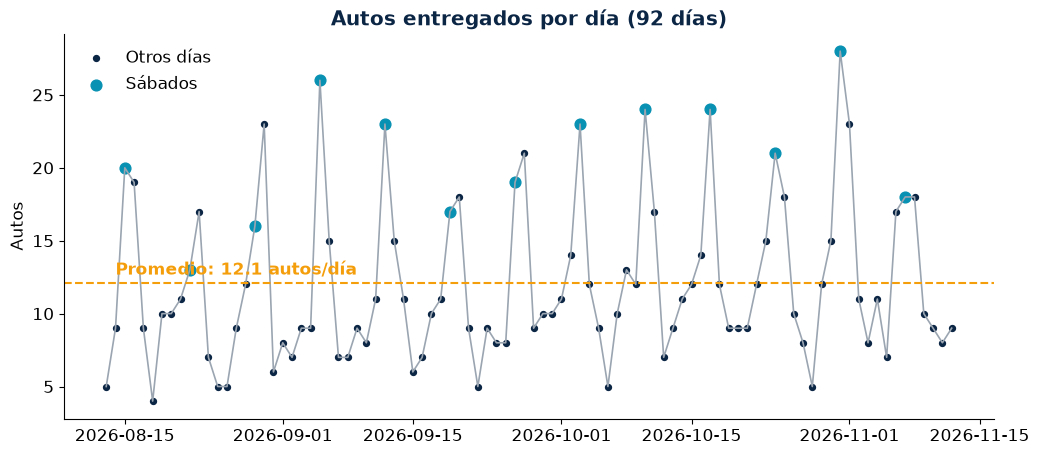

In [3]:
HASTA = pd.Timestamp("2026-11-12")
por_dia = lavados.groupby("dia").size()
# Un día sin autos no aparece en los registros: se completa con 0
dias = pd.date_range(por_dia.index.min(), HASTA, freq="D")
y = por_dia.reindex(dias, fill_value=0).astype(float)

ax = plt.gca()
ax.plot(y.index, y.values, color=GRIS, lw=1.2)
es_sabado = y.index.day_of_week == 5
ax.scatter(y.index[~es_sabado], y[~es_sabado], s=18, color=MARCA, label="Otros días")
ax.scatter(y.index[es_sabado], y[es_sabado], s=60, color=ACENTO, label="Sábados")
ax.axhline(y.mean(), color=NARANJA, ls="--")
ax.text(y.index[1], y.mean() + 0.6, f"Promedio: {y.mean():.1f} autos/día", color=NARANJA, fontweight="bold")
ax.set_title(f"Autos entregados por día ({len(y)} días)")
ax.set_ylabel("Autos"); ax.legend(frameon=False)
plt.show()

Se ve un patrón: los **sábados** (celeste) siempre están arriba. Eso es lo que el modelo tiene que aprender.

### 1.2 Variables: lo que se sabe de un día antes de que ocurra

| Variable | Valor | Por qué |
|---|---|---|
| `lun` … `dom` | 1 si es ese día, 0 si no (*one-hot*) | El viernes no está "entre" el jueves y el sábado: cada día es una categoría propia |
| `dia_de_pago` | 1 los días 14-16 y 29-1 | Con el sueldo en el bolsillo, más gente lava el auto |
| `feriado` | 1 en feriados nacionales | Cambia la rutina |
| `tendencia` | Meses desde el inicio | Si el negocio crece o baja con el tiempo |

In [4]:
DIAS = ["lun", "mar", "mie", "jue", "vie", "sab", "dom"]
FERIADOS = {date(2026, 8, 6), date(2026, 8, 30), date(2026, 10, 8), date(2026, 11, 1),
            date(2026, 12, 8), date(2026, 12, 9), date(2026, 12, 25)}
INICIO = y.index.min()

def variables(fechas):
    tabla = pd.DataFrame(index=fechas)
    for numero, nombre in enumerate(DIAS):
        tabla[nombre] = (fechas.day_of_week == numero).astype(int)
    tabla["dia_de_pago"] = fechas.day.isin([14, 15, 16, 29, 30, 31, 1]).astype(int)
    tabla["feriado"] = [int(f.date() in FERIADOS) for f in fechas]
    tabla["tendencia"] = (fechas - INICIO).days / 30
    return tabla

X = variables(y.index)
X.assign(autos=y).head(8)

,lun,mar,mie,jue,vie,sab,dom,dia_de_pago,feriado,tendencia,autos
2026-08-13,0,0,0,1,0,0,0,0,0,0.000000,5.0
2026-08-14,0,0,0,0,1,0,0,1,0,0.033333,9.0
2026-08-15,0,0,0,0,0,1,0,1,0,0.066667,20.0
2026-08-16,0,0,0,0,0,0,1,1,0,0.100000,19.0
2026-08-17,1,0,0,0,0,0,0,0,0,0.133333,9.0
2026-08-18,0,1,0,0,0,0,0,0,0,0.166667,4.0
2026-08-19,0,0,1,0,0,0,0,0,0,0.200000,10.0
2026-08-20,0,0,0,1,0,0,0,0,0,0.233333,10.0


### 1.3 Tres candidatos

| Candidato | Cómo predice |
|---|---|
| **Referencia** | El promedio de autos de ese día de la semana. Es la vara: si un modelo no la supera, no sirve. |
| **Ridge** (`sklearn.linear_model.Ridge`) | Una **regresión lineal**: suma un peso por cada variable. La penalización (`alpha`) evita pesos exagerados cuando hay pocos datos. |
| **Random Forest** (`sklearn.ensemble.RandomForestRegressor`) | 300 árboles de decisión que votan. Capta combinaciones raras, pero con pocos datos puede memorizar ruido. |

In [5]:
class PromedioPorDia:
    """Referencia: el promedio de autos de cada día de la semana."""
    def fit(self, X, y):
        self.promedios = pd.Series(np.asarray(y)).groupby(X[DIAS].values.argmax(axis=1)).mean()
        return self
    def predict(self, X):
        return self.promedios.reindex(X[DIAS].values.argmax(axis=1)).values

CANDIDATOS = {
    "Referencia": lambda: PromedioPorDia(),
    "Ridge": lambda: Ridge(alpha=1.0),
    "Random Forest": lambda: RandomForestRegressor(n_estimators=300, max_depth=5,
                                                   min_samples_leaf=3, random_state=2026),
}

### 1.4 La prueba: como se usaría de verdad

No basta con que el modelo acierte sobre los días que ya vio. Se simula lo que pasará en el lavadero: **cada una de las últimas 4 semanas se predice solo con los días anteriores a ella**, sin ver su resultado. Después se compara con lo que pasó.

La métrica es el **MAE** (error absoluto medio): cuántos autos se equivoca en promedio por día.

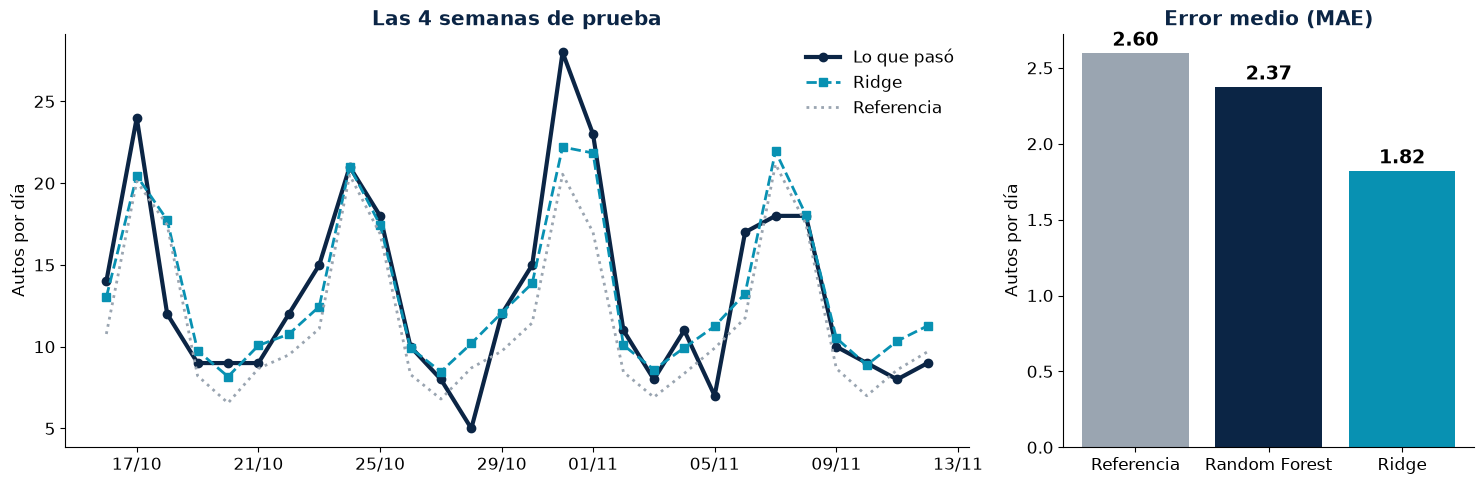

Gana Ridge: se equivoca en 1.82 autos por día, 30 % menos que la referencia.


In [6]:
SEMANAS = 4
predicho = {}
for nombre, crear in CANDIDATOS.items():
    p = []
    for semana in range(SEMANAS, 0, -1):
        corte = len(y) - 7 * semana                     # todo lo anterior a esa semana
        modelo = crear().fit(X.iloc[:corte], y.iloc[:corte])
        p.extend(modelo.predict(X.iloc[corte:corte + 7]))
    predicho[nombre] = np.array(p)

real = y.iloc[-7 * SEMANAS:]
mae = {n: np.mean(np.abs(real.values - p)) for n, p in predicho.items()}

fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2.2, 1]})
a1.plot(real.index, real.values, color=MARCA, lw=3, marker="o", label="Lo que pasó")
a1.plot(real.index, predicho["Ridge"], color=ACENTO, lw=2, ls="--", marker="s", label="Ridge")
a1.plot(real.index, predicho["Referencia"], color=GRIS, lw=2, ls=":", label="Referencia")
a1.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
a1.set_title("Las 4 semanas de prueba"); a1.set_ylabel("Autos por día"); a1.legend(frameon=False)

orden = ["Referencia", "Random Forest", "Ridge"]
barras = a2.bar(orden, [mae[n] for n in orden], color=[GRIS, MARCA, ACENTO])
for b in barras:
    a2.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.05, f"{b.get_height():.2f}",
            ha="center", fontweight="bold", fontsize=14)
a2.set_title("Error medio (MAE)"); a2.set_ylabel("Autos por día")
plt.tight_layout(); plt.show()

elegido = min(mae, key=mae.get)
mejora = (1 - mae[elegido] / mae["Referencia"]) * 100
print(f"Gana {elegido}: se equivoca en {mae[elegido]:.2f} autos por día, {mejora:.0f} % menos que la referencia.")

**Ridge gana.** Con 3 meses de datos, el modelo más simple le gana al bosque de árboles: hay pocos días para que el Random Forest aprenda combinaciones sin memorizar ruido. Y además es el más fácil de explicar, como se ve abajo.

### 1.5 Cómo predice Ridge: la representación del modelo

Ridge es una suma. El modelo entrenado es **un número base más un peso por cada variable**:

$$\text{autos} = \text{base} + w_{lun}\cdot lun + \dots + w_{sab}\cdot sab + w_{pago}\cdot pago + w_{feriado}\cdot feriado + w_{tend}\cdot tendencia$$

Entrenarlo es encontrar esos pesos. Al final se entrena con **todos** los días.

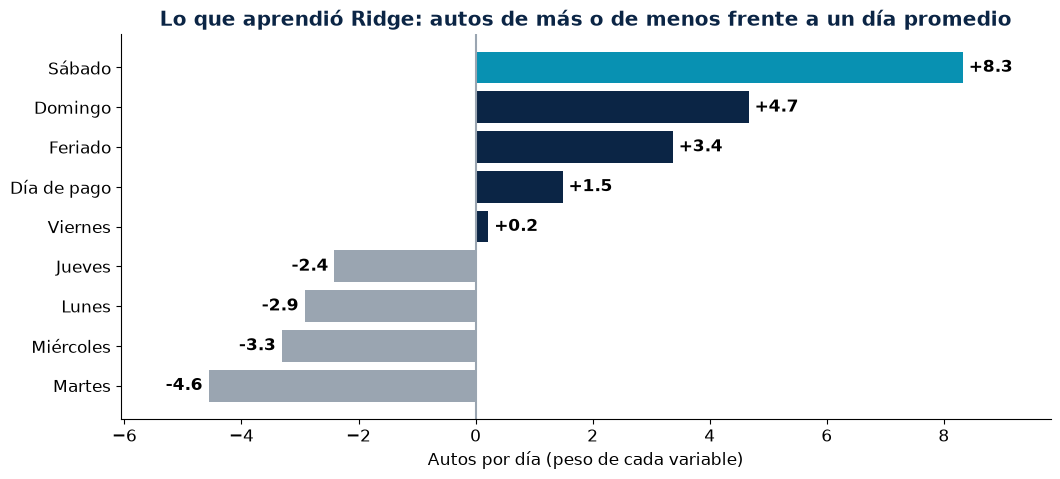

In [7]:
ridge = Ridge(alpha=1.0).fit(X, y)
pesos = pd.Series(ridge.coef_, index=X.columns)

# Cada peso es lo que esa variable suma o resta a la base (un día promedio)
etiquetas = {"lun": "Lunes", "mar": "Martes", "mie": "Miércoles", "jue": "Jueves",
             "vie": "Viernes", "sab": "Sábado", "dom": "Domingo"}
efecto = pd.Series({etiquetas[d]: pesos[d] for d in etiquetas})
efecto["Feriado"] = pesos["feriado"]
efecto["Día de pago"] = pesos["dia_de_pago"]
efecto = efecto.sort_values()

colores = [ACENTO if v == efecto.max() else (MARCA if v >= 0 else GRIS) for v in efecto]
barras = plt.barh(efecto.index, efecto.values, color=colores)
for b, v in zip(barras, efecto.values):
    plt.text(v + (0.1 if v >= 0 else -0.1), b.get_y() + b.get_height() / 2, f"{v:+.1f}",
             va="center", ha="left" if v >= 0 else "right", fontweight="bold")
plt.axvline(0, color=GRIS)
plt.xlim(efecto.min() - 1.5, efecto.max() + 1.5)
plt.title("Lo que aprendió Ridge: autos de más o de menos frente a un día promedio")
plt.xlabel("Autos por día (peso de cada variable)")
plt.show()

Así se lee el modelo completo: **el sábado suma unos 8 autos**, el día de pago suma algunos más, un feriado cambia la cuenta. Nada de caja negra: el dueño puede entender por qué el sistema le dice lo que le dice.

#### Ejemplo: cómo arma la predicción de un sábado

El modelo parte de la base y va sumando el peso de cada variable que ese día vale 1.

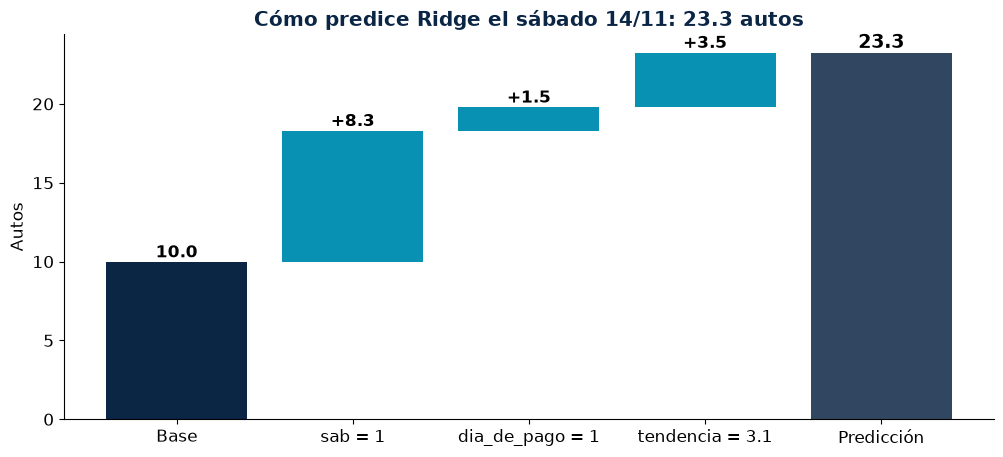

Comprobación con scikit-learn: 23.3


In [8]:
dia = pd.Timestamp("2026-11-14")            # el sábado siguiente al corte
x_dia = variables(pd.DatetimeIndex([dia])).iloc[0]

pasos = [("Base", ridge.intercept_)]
for nombre, valor in x_dia.items():
    aporte = pesos[nombre] * valor
    if abs(aporte) > 0.05:
        pasos.append((f"{nombre} = {valor:g}", aporte))
total = sum(a for _, a in pasos)

# Gráfico de cascada: cada barra empieza donde terminó la anterior
acumulado = 0
for i, (nombre, aporte) in enumerate(pasos):
    color = MARCA if i == 0 else (ACENTO if aporte > 0 else NARANJA)
    plt.bar(i, aporte, bottom=acumulado if i else 0, color=color)
    plt.text(i, (acumulado if i else 0) + aporte + 0.3, f"{aporte:+.1f}" if i else f"{aporte:.1f}",
             ha="center", fontweight="bold")
    acumulado += aporte
plt.bar(len(pasos), total, color=MARCA, alpha=0.85)
plt.text(len(pasos), total + 0.3, f"{total:.1f}", ha="center", fontweight="bold", fontsize=14)
plt.xticks(range(len(pasos) + 1), [n for n, _ in pasos] + ["Predicción"])
plt.title(f"Cómo predice Ridge el sábado {dia:%d/%m}: {total:.1f} autos")
plt.ylabel("Autos")
plt.show()

print("Comprobación con scikit-learn:", ridge.predict(x_dia.to_frame().T)[0].round(1))

### 1.6 La predicción de los próximos 14 días

El margen sale de la prueba: el 80 % de los errores de Ridge en las 4 semanas cayó dentro de ese rango.

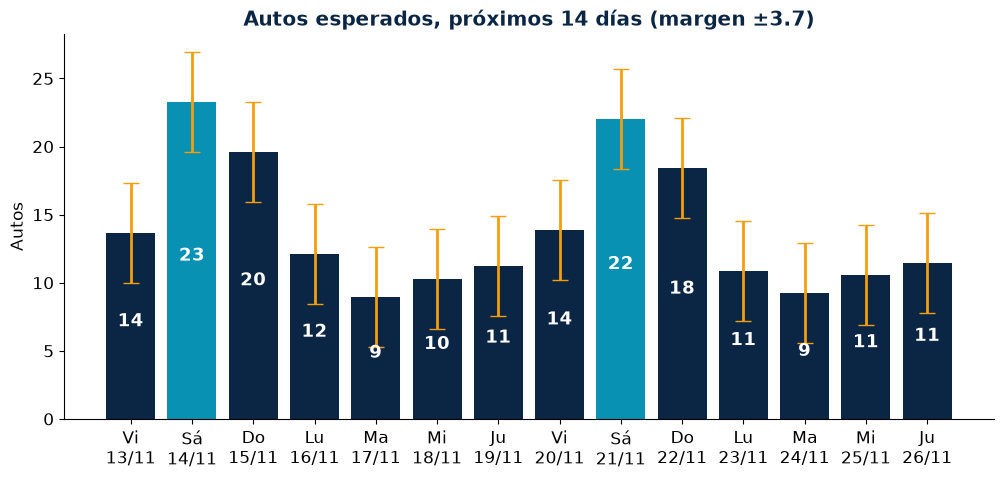

In [9]:
margen = np.quantile(np.abs(real.values - predicho["Ridge"]), 0.8)
futuras = pd.date_range(HASTA + pd.Timedelta(days=1), periods=14, freq="D")
estimado = np.clip(ridge.predict(variables(futuras)), 0, None)

colores = [ACENTO if f.day_of_week == 5 else MARCA for f in futuras]
plt.bar(range(14), estimado, color=colores)
plt.errorbar(range(14), estimado, yerr=margen, fmt="none", ecolor=NARANJA, capsize=6, lw=2)
for i, v in enumerate(estimado):
    plt.text(i, v / 2, f"{v:.0f}", ha="center", color="white", fontweight="bold", fontsize=13)
nombre_dia = ["Lu", "Ma", "Mi", "Ju", "Vi", "Sá", "Do"]
plt.xticks(range(14), [f"{nombre_dia[f.day_of_week]}\n{f:%d/%m}" for f in futuras])
plt.title(f"Autos esperados, próximos 14 días (margen ±{margen:.1f})")
plt.ylabel("Autos")
plt.show()

### 1.7 ¿Cómo ayuda al dueño?

Hoy el dueño decide cuántos lavadores llamar **a ojo**. Con la predicción en el tablero de LavaSmart:

| Decisión | Sin el modelo | Con el modelo |
|---|---|---|
| **Cuántos lavadores convocar** | A ojo o por costumbre | Según los autos esperados: si un lavador atiende unos 4-5 autos al día, 21 autos piden 5 lavadores y 10 autos, 2 o 3 |
| **Costo de personal** | Lavadores de sobra en días flojos | Menos sueldos fijos pagados sin trabajo |
| **Días cargados** | Clientes esperando o que se van | Personal completo el sábado y en quincena |
| **Insumos** | Se compran cuando se acaban | Se compran según la semana que viene |
| **Promociones** | Cualquier día | En los días flojos, para llenarlos |

Y se equivoca **menos que el promedio** con el que el dueño ya calcula de memoria, con un margen conocido.

---
# Modelo 2 · Segmentación de clientes

**Pregunta:** ¿quiénes son mis clientes y cuánto vale cada grupo?

**Idea:** nadie le dice al modelo qué grupos existen (**aprendizaje no supervisado**). Se describe a cada cliente con tres números y K-Means junta a los que se parecen.

Recorrido: **lavados por placa → RFM → logaritmo y escala → K-Means con 3, 4 y 5 grupos → elegir por silueta → nombrar los grupos.**

### 2.1 RFM: cada cliente en tres números

| Letra | Qué mide | Cómo se calcula |
|---|---|---|
| **R**ecencia | Hace cuánto vino | Días desde su última visita |
| **F**recuencia | Cuántas veces vino | Número de lavados |
| **M**onetario | Cuánto dejó | Soles pagados en total (lo cobrado, no la tarifa) |

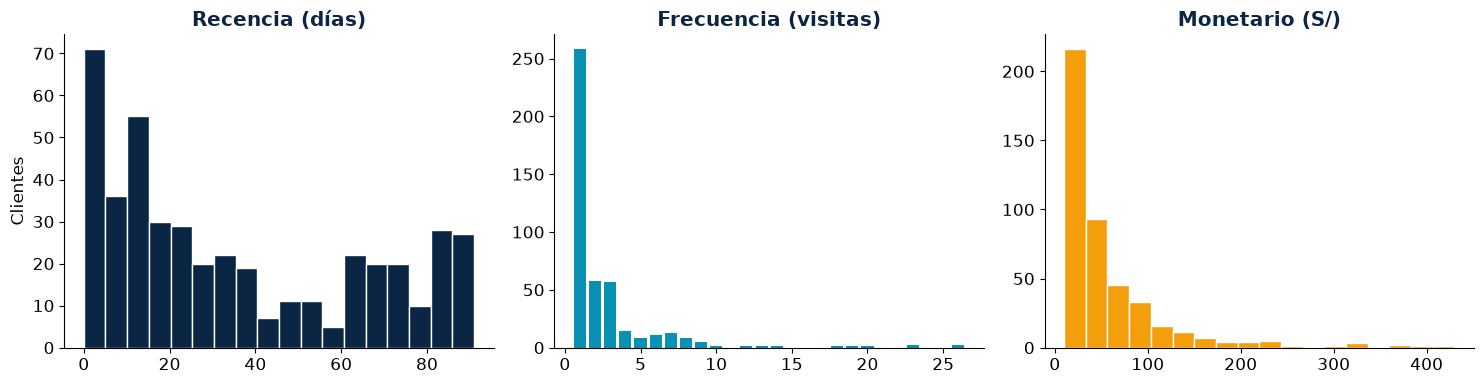

,recencia,frecuencia,monetario
cliente,,,
1,3,26,430.0
2,16,3,82.0
3,91,1,24.0
4,14,3,95.0
5,11,3,60.0


In [10]:
corte = HASTA
rfm = lavados.groupby("cliente").agg(
    ultima=("dia", "max"), frecuencia=("dia", "size"), monetario=("monto", "sum"))
rfm["recencia"] = (corte - rfm["ultima"]).dt.days
rfm = rfm[["recencia", "frecuencia", "monetario"]]

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
axs[0].hist(rfm["recencia"], bins=18, color=MARCA, edgecolor="white"); axs[0].set_title("Recencia (días)")
cuenta = rfm["frecuencia"].value_counts().sort_index()
axs[1].bar(cuenta.index, cuenta.values, color=ACENTO); axs[1].set_title("Frecuencia (visitas)")
axs[2].hist(rfm["monetario"], bins=18, color=NARANJA, edgecolor="white"); axs[2].set_title("Monetario (S/)")
axs[0].set_ylabel("Clientes")
plt.tight_layout(); plt.show()
rfm.head()

### 2.2 Preparar los números antes de agrupar

K-Means agrupa por **distancia**. Hay dos problemas:

1. **Escalas distintas:** los soles van de 15 a cientos, las visitas de 1 a 15. Sin corregirlo, el dinero decidiría todo. `StandardScaler` deja las tres variables con promedio 0 y la misma dispersión.
2. **Valores extremos:** unos pocos clientes muy frecuentes estiran la escala y aplastan al resto. Un **logaritmo** (`np.log1p`) en frecuencia y monetario los acerca.

In [11]:
escala = StandardScaler()
Z = escala.fit_transform(np.column_stack([
    rfm["recencia"], np.log1p(rfm["frecuencia"]), np.log1p(rfm["monetario"])]))
pd.DataFrame(Z, columns=["recencia", "log frecuencia", "log monetario"]).describe().round(2).loc[["mean", "std"]]

,recencia,log frecuencia,log monetario
mean,0.0,-0.0,-0.0
std,1.0,1.0,1.0


### 2.3 K-Means: ¿cuántos grupos?

K-Means (`sklearn.cluster.KMeans`) funciona así:
1. Pone **k centros** al azar.
2. Asigna cada cliente al **centro más cercano**.
3. Mueve cada centro al **promedio** de sus clientes.
4. Repite 2 y 3 hasta que los centros no se mueven.

Hay que decirle cuántos grupos (k). Se prueban 3, 4 y 5, y se elige con el **coeficiente de silueta**: para cada cliente compara qué tan cerca está de su grupo frente al grupo vecino. Va de -1 a 1; más alto, grupos más separados.

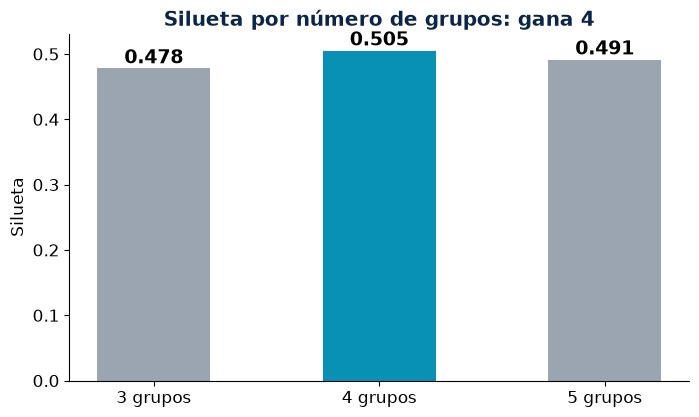

In [12]:
siluetas, modelos = {}, {}
for k in (3, 4, 5):
    modelos[k] = KMeans(n_clusters=k, n_init=20, random_state=2026).fit(Z)
    siluetas[k] = silhouette_score(Z, modelos[k].labels_)

k = max(siluetas, key=siluetas.get)
kmeans = modelos[k]
barras = plt.bar([f"{g} grupos" for g in siluetas], siluetas.values(),
                 color=[ACENTO if g == k else GRIS for g in siluetas], width=0.5)
for b in barras:
    plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.008, f"{b.get_height():.3f}",
             ha="center", fontweight="bold", fontsize=14)
plt.title(f"Silueta por número de grupos: gana {k}"); plt.ylabel("Silueta")
plt.gcf().set_size_inches(8, 4.5); plt.show()

### 2.4 Ponerle nombre a cada grupo

K-Means devuelve grupos 0, 1, 2, 3, que no le dicen nada al dueño. Se nombran por sus **promedios**:
- el de **más visitas**: *Frecuentes*;
- el que **hace más tiempo no viene**: *Inactivos*;
- el que vino **una sola vez y hace poco**: *Nuevos*;
- el resto: *Ocasionales*.

In [13]:
rfm["grupo"] = kmeans.labels_
perfil = rfm.groupby("grupo")[["recencia", "frecuencia", "monetario"]].mean()

nombres, resto = {}, perfil.copy()
g = resto["frecuencia"].idxmax(); nombres[g] = "Frecuentes"; resto = resto.drop(g)
g = resto["recencia"].idxmax();   nombres[g] = "Inactivos";  resto = resto.drop(g)
g = resto["frecuencia"].idxmin(); nombres[g] = "Nuevos";     resto = resto.drop(g)
for g in resto.index: nombres[g] = "Ocasionales"

rfm["segmento"] = rfm["grupo"].map(nombres)
ORDEN = ["Frecuentes", "Ocasionales", "Nuevos", "Inactivos"]
COLOR = {"Frecuentes": ACENTO, "Ocasionales": MARCA, "Nuevos": NARANJA, "Inactivos": GRIS}

tabla = rfm.groupby("segmento").agg(clientes=("recencia", "size"), recencia_dias=("recencia", "mean"),
                                     visitas=("frecuencia", "mean"), gasto_S=("monetario", "mean"))
tabla.loc[ORDEN].round(1)

,clientes,recencia_dias,visitas,gasto_S
segmento,,,,
Frecuentes,54,5.5,9.3,185.4
Ocasionales,125,13.9,2.7,65.4
Nuevos,120,26.0,1.0,24.8
Inactivos,144,73.7,1.0,25.2


### 2.5 La representación del modelo: los grupos y sus centros

Cada punto es un cliente; la **X** es el centro de su grupo. Esos 4 centros **son** el modelo entrenado: todo lo que K-Means aprendió está en ellos.

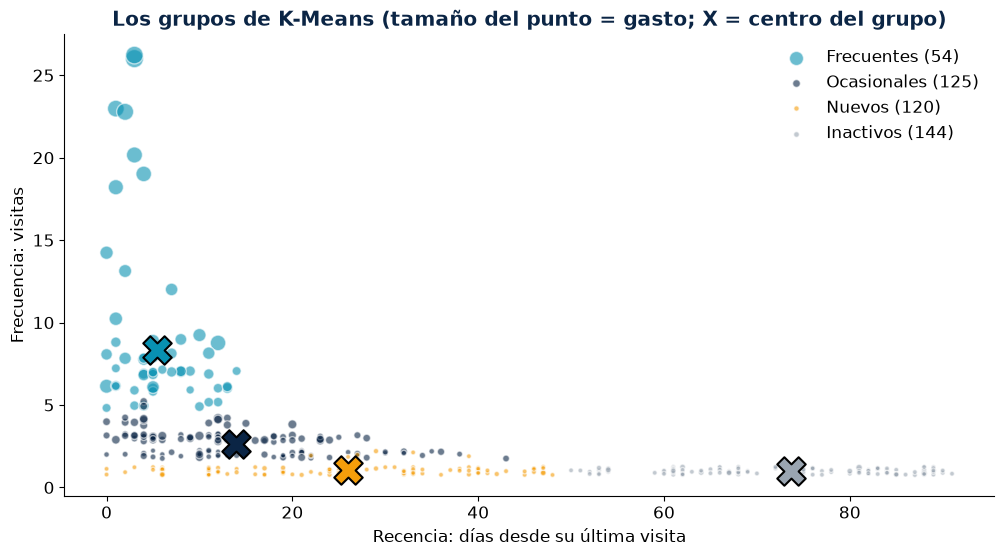

In [14]:
centros = pd.DataFrame(escala.inverse_transform(kmeans.cluster_centers_),
                       columns=["recencia", "log_f", "log_m"])
centros["frecuencia"] = np.expm1(centros["log_f"])

rng = np.random.default_rng(1)
plt.figure(figsize=(12, 6))
for seg in ORDEN:
    sub = rfm[rfm["segmento"] == seg]
    plt.scatter(sub["recencia"], sub["frecuencia"] + rng.uniform(-0.25, 0.25, len(sub)),
                s=np.clip(sub["monetario"] / 2.5, 12, 250), color=COLOR[seg], alpha=0.6,
                edgecolor="white", label=f"{seg} ({len(sub)})")
for g, c in centros.iterrows():
    plt.scatter(c["recencia"], c["frecuencia"], marker="X", s=420, color=COLOR[nombres[g]],
                edgecolor="black", lw=1.5, zorder=5)
plt.xlabel("Recencia: días desde su última visita"); plt.ylabel("Frecuencia: visitas")
plt.title("Los grupos de K-Means (tamaño del punto = gasto; X = centro del grupo)")
plt.legend(frameon=False, loc="upper right")
plt.show()

#### Ejemplo: cómo clasifica a un cliente

Para un cliente, K-Means calcula la distancia a cada centro y lo pone en el **más cercano**. Por ejemplo, un auto que vino 5 veces, gastó S/ 120 y volvió hace 6 días:

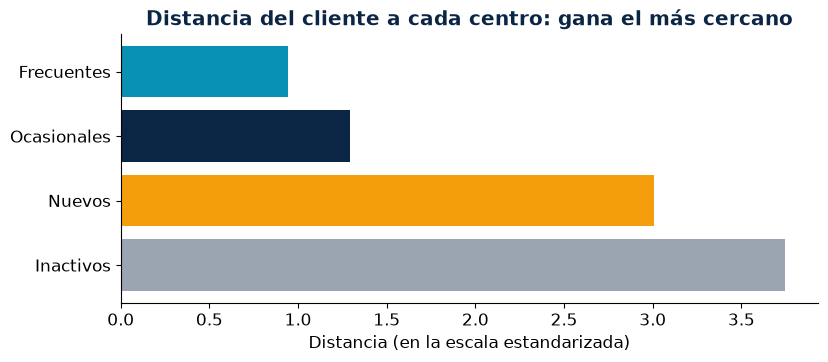

K-Means lo asigna a: Frecuentes


In [15]:
nuevo = escala.transform([[6, np.log1p(5), np.log1p(120)]])
distancias = np.linalg.norm(kmeans.cluster_centers_ - nuevo, axis=1)

orden_g = np.argsort(distancias)
plt.barh([nombres[g] for g in orden_g][::-1], distancias[orden_g][::-1],
         color=[COLOR[nombres[g]] for g in orden_g][::-1])
plt.title("Distancia del cliente a cada centro: gana el más cercano")
plt.xlabel("Distancia (en la escala estandarizada)")
plt.gcf().set_size_inches(9, 3.5); plt.show()

print("K-Means lo asigna a:", nombres[kmeans.predict(nuevo)[0]])

### 2.6 ¿Cómo ayuda al dueño?

El dueño ve en el tablero cuántos clientes hay en cada segmento y la lista de placas de cada uno. Lo más útil es comparar **cuántos clientes son** con **cuánto dinero dejan**:

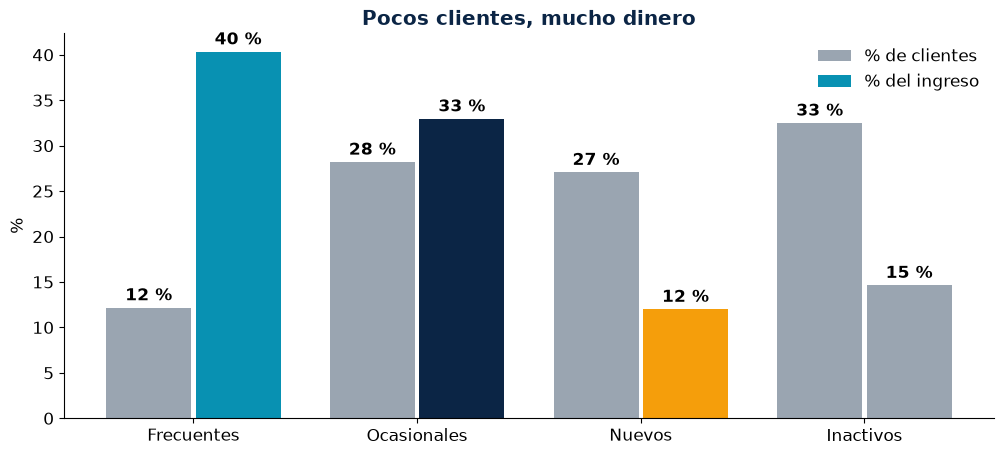

Si vuelve 1 de cada 10 inactivos: 14 clientes, unos S/ 353 (a su gasto promedio).


In [16]:
pc = rfm.groupby("segmento").size() / len(rfm) * 100
pm = rfm.groupby("segmento")["monetario"].sum() / rfm["monetario"].sum() * 100
xx = np.arange(len(ORDEN))
b1 = plt.bar(xx - 0.2, [pc[s] for s in ORDEN], 0.38, color=GRIS, label="% de clientes")
b2 = plt.bar(xx + 0.2, [pm[s] for s in ORDEN], 0.38, color=[COLOR[s] for s in ORDEN], label="% del ingreso")
for b in list(b1) + list(b2):
    plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.8, f"{b.get_height():.0f} %",
             ha="center", fontweight="bold")
plt.xticks(xx, ORDEN); plt.ylabel("%"); plt.legend(frameon=False)
plt.title("Pocos clientes, mucho dinero")
plt.show()

inactivos = rfm[rfm["segmento"] == "Inactivos"]
recuperados = round(len(inactivos) * 0.10)
print(f"Si vuelve 1 de cada 10 inactivos: {recuperados} clientes,",
      f"unos S/ {recuperados * inactivos['monetario'].mean():.0f} (a su gasto promedio).")

| Segmento | Qué significa | Qué puede hacer el dueño |
|---|---|---|
| **Frecuentes** | Pocos, pero dejan la mayor parte del ingreso | Cuidarlos: tarjeta de fidelidad, trato preferente. Perder uno cuesta caro |
| **Ocasionales** | Vienen de vez en cuando | Un recordatorio por WhatsApp a las 2 semanas de su último lavado |
| **Nuevos** | Vinieron una vez, hace poco | Descuento en la segunda visita para que vuelvan |
| **Inactivos** | Hace más de dos meses que no vienen | Una oferta por mensaje para recuperarlos |

Antes el dueño **no sabía quiénes eran sus clientes**: el cuaderno no anotaba placas. Ahora sabe a quién cuidar, a quién llamar y cuánto vale hacerlo.

---
### Resumen

| | Demanda | Segmentación |
|---|---|---|
| Librería | scikit-learn: `Ridge` (y `RandomForestRegressor` como candidato) | scikit-learn: `KMeans`, `StandardScaler`, `silhouette_score` |
| Entrada | Autos por día + día de la semana, pago, feriado, tendencia | Recencia, frecuencia y monetario por cliente |
| Cómo predice | Base + suma de pesos de cada variable | Asigna cada cliente al centro más cercano |
| Cómo se evaluó | MAE en 4 semanas sin ver: mejor que la referencia | Silueta entre 3, 4 y 5 grupos |
| Decisión del dueño | Cuántos lavadores convocar y cuándo | A quién cuidar, a quién llamar |
| En LavaSmart | Corre cada lunes (GitHub Actions) y aparece en el tablero | Igual: tablero, con la lista por segmento |